# Transfer Learning con ResNet18: Frutas Frescas vs Podridas
### Proyecto final — Inteligencia Artificial (Deep Learning) — Notebook 02 (comparación)
---
En el notebook `01` entrenamos una CNN **desde cero**: empezó con pesos aleatorios y tuvo que aprender todo con nuestras ~9,000 imágenes. Aquí respondemos la pregunta del assignment **"¿cómo mejorar la accuracy?"** con **transfer learning**.

**¿Qué es transfer learning?** Tomamos una red que **ya fue entrenada** con **ImageNet** (1.2 millones de fotos de 1,000 clases) y la reutilizamos. Sus capas convolucionales ya saben detectar bordes, colores, texturas y formas. Solo le cambiamos la **última capa** (la que decide la clase) por una nueva de 6 salidas y la entrenamos con nuestras frutas. Es como contratar a alguien que ya sabe "ver" y solo enseñarle qué es una fruta podrida.

**ResNet18** es una CNN de 18 capas (Microsoft, 2015). Su gran idea son las **conexiones residuales**: cada bloque suma su entrada a su salida (`x + F(x)`). Así el gradiente fluye mejor y se pueden entrenar redes muy profundas.

**Plan:**
1. Librerías, hiperparámetros y transforms (ahora con la normalización de ImageNet)
2. Los mismos datasets y el mismo split que el notebook 01, para comparar en igualdad de condiciones
3. **Etapa 1:** congelar toda la red y entrenar solo la nueva capa final (3 epochs)
4. **Etapa 2 (opcional):** "descongelar" `layer4` y hacer *fine-tuning* con un learning rate chico
5. Las mismas métricas y gráficos que el notebook 01
6. **Tabla comparativa:** CNN propia vs ResNet18

## 1. Importar librerías

Las mismas del notebook 01, más `torchvision.models`, que trae arquitecturas famosas con sus pesos preentrenados.

In [1]:
import sys  # Para importar src/modelo.py (la CNN propia, para la comparación)
import time  # Para medir tiempos de entrenamiento e inferencia
import copy  # Para copiar los pesos del mejor epoch
import json  # Para leer y guardar métricas
import random  # Para elegir imágenes al azar
from pathlib import Path  # Rutas de archivos

import numpy as np  # Arrays
import matplotlib.pyplot as plt  # Gráficos
import seaborn as sns  # Matriz de confusión
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # Métricas
from PIL import Image, ImageOps  # Fotos propias

import torch  # PyTorch
import torchvision  # Datasets y modelos de visión
import torchvision.transforms as transforms  # Preprocesamiento
import torch.nn as nn  # Capas y pérdidas
from torch.utils.data import Subset, DataLoader  # Split y carga por batches
from torchvision.models import resnet18, ResNet18_Weights  # ResNet18 y sus pesos preentrenados en ImageNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU si hay
print("Dispositivo:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

SEMILLA = 42  # La MISMA semilla que el notebook 01, para que el split train/validación sea idéntico
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)  # Fija todas las semillas

RAIZ = Path("..")  # Raíz del proyecto
DATA_DIR, MODELS_DIR, OUTPUTS_DIR = RAIZ / "data", RAIZ / "models", RAIZ / "outputs"  # Carpetas del proyecto
MODELS_DIR.mkdir(exist_ok=True); OUTPUTS_DIR.mkdir(exist_ok=True)  # Crea las carpetas si no existen

Dispositivo: cuda | NVIDIA GeForce RTX 4070 Laptop GPU


## 2. Hiperparámetros

Hay dos etapas con learning rates distintos:
- **Etapa 1 (`LR_CABEZA = 0.001`):** solo se entrena la capa nueva, que empieza con pesos aleatorios, así que puede aprender rápido.
- **Etapa 2 (`LR_FINE = 0.0001`, 10 veces menor):** ajustamos también `layer4`, que **ya tiene** buenos pesos de ImageNet. Con un LR grande los "romperíamos" (a esto se le llama *catastrophic forgetting*); con uno chico solo los afinamos.

Con transfer learning bastan **pocos epochs**: la red ya sabe ver.

In [2]:
IMG_SIZE = 224        # ResNet18 fue entrenada con imágenes de 224x224 (en el notebook 01 usamos 128)
BATCH_SIZE = 64       # Igual que el notebook 01
LR_CABEZA = 0.001     # Learning rate de la Etapa 1 (solo la capa final)
EPOCHS_CABEZA = 3     # Epochs de la Etapa 1
HACER_ETAPA2 = True   # (Opcional) Etapa 2: fine-tuning de layer4
LR_FINE = 0.0001      # Learning rate de la Etapa 2 (10 veces más chico)
EPOCHS_FINE = 4       # Epochs de la Etapa 2
VAL_SPLIT = 0.15      # Igual que el notebook 01
NUM_WORKERS = 4       # Si Jupyter se cuelga en Windows, poner 0
QUICK_RUN = False     # True = prueba rápida (~500 imágenes, 1 epoch por etapa)

if QUICK_RUN:
    EPOCHS_CABEZA, EPOCHS_FINE = 1, 1  # Solo 1 epoch por etapa en modo prueba
    print("QUICK_RUN activado: los resultados NO son representativos.")

## 3. Transforms: ¿por qué cambian?

Un modelo preentrenado espera las imágenes **igual que como las vio al entrenarse**. ResNet18 se entrenó con:
- imágenes de **224x224**;
- la normalización **de ImageNet**: `mean=[0.485, 0.456, 0.406]` y `std=[0.229, 0.224, 0.225]`, que son la media y la desviación estándar reales de los píxeles de ImageNet en cada canal R, G y B.

Si le pasáramos imágenes normalizadas con 0.5/0.5, sus filtros recibirían números en una escala distinta a la que "conocen" y funcionarían peor. El data augmentation es el mismo que en el notebook 01.

In [3]:
MEAN = [0.485, 0.456, 0.406]  # Media de ImageNet por canal (R, G, B)
STD = [0.229, 0.224, 0.225]   # Desviación estándar de ImageNet por canal

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # 224x224, como espera ResNet18
    transforms.RandomHorizontalFlip(),  # Mismo augmentation que el notebook 01
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),  # (Opcional) brillo/contraste; sin tocar el tono
    transforms.ToTensor(),  # A tensor en [0, 1]
    transforms.Normalize(MEAN, STD),  # Normalización de ImageNet
])
test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # Mismo tamaño
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),  # Misma normalización
])

## 4. Datasets y DataLoaders

Es **exactamente el mismo split** que el notebook 01 (misma semilla y mismo `VAL_SPLIT`). Así la comparación entre los dos modelos es justa: ambos se entrenan, se validan y se evalúan con las mismas imágenes.

In [4]:
full_train_aug = torchvision.datasets.ImageFolder(DATA_DIR / "train", transform=train_transform)  # Train con augmentation
full_train_eval = torchvision.datasets.ImageFolder(DATA_DIR / "train", transform=test_transform)  # Train sin augmentation (para validar)
test_dataset = torchvision.datasets.ImageFolder(DATA_DIR / "test", transform=test_transform)  # Test

clases = full_train_aug.classes  # Orden alfabético de las carpetas
NOMBRES_ES = {"freshapples": "Manzana fresca", "freshbanana": "Banana fresca", "freshoranges": "Naranja fresca",
              "rottenapples": "Manzana podrida", "rottenbanana": "Banana podrida", "rottenoranges": "Naranja podrida"}
nombres = [NOMBRES_ES[c] for c in clases]  # Nombres en español en el orden de los índices

g = torch.Generator().manual_seed(SEMILLA)  # Mismo generador que en el notebook 01
indices = torch.randperm(len(full_train_aug), generator=g).tolist()  # Misma permutación
n_val = int(len(indices) * VAL_SPLIT)
val_idx, train_idx = indices[:n_val], indices[n_val:]  # Mismo split
if QUICK_RUN:
    train_idx, val_idx = train_idx[:400], val_idx[:100]

train_dataset = Subset(full_train_aug, train_idx)
val_dataset = Subset(full_train_eval, val_idx)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=(device.type == "cuda"), persistent_workers=(NUM_WORKERS > 0))
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)
print(f"Train: {len(train_dataset)} | Validación: {len(val_dataset)} | Test: {len(test_dataset)}")

def desnormalizar(img):
    """Tensor normalizado con ImageNet (C, H, W) -> array (H, W, C) en [0, 1] para mostrarlo."""
    img = img.cpu() * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)  # x * std + mean, por canal
    return img.clamp(0, 1).permute(1, 2, 0).numpy()

Train: 9266 | Validación: 1635 | Test: 2698


## 5. Cargar ResNet18 preentrenada y adaptarla

1. `resnet18(weights=ResNet18_Weights.DEFAULT)` descarga los pesos de ImageNet (~45 MB, solo la primera vez).
2. **Congelamos** todos los parámetros (`requires_grad = False`): el optimizador no los va a cambiar y PyTorch ni siquiera calcula sus gradientes, así que es mucho más rápido.
3. Reemplazamos la última capa: ImageNet tiene 1,000 clases (`fc: 512 → 1000`) y nosotros 6, así que ponemos `nn.Linear(512, 6)`. Una capa nueva tiene `requires_grad = True` por defecto, así que **solo ella** se entrena.

Estructura de ResNet18: `conv1 → layer1 → layer2 → layer3 → layer4 → avgpool → fc`. El `avgpool` (*global average pooling*) promedia cada uno de los 512 mapas finales en un solo número. Por eso la capa `fc` tiene solo 512 entradas y no 32,768 como nuestro `fc1`.

In [5]:
modelo = resnet18(weights=ResNet18_Weights.DEFAULT)  # ResNet18 con pesos preentrenados en ImageNet

for p in modelo.parameters():  # Recorre TODOS los parámetros...
    p.requires_grad = False  # ...y los congela (no se entrenan)

modelo.fc = nn.Linear(modelo.fc.in_features, len(clases))  # Capa final nueva: 512 -> 6 (esta SÍ se entrena)
modelo = modelo.to(device)  # A la GPU

def contar_parametros(m):
    """Devuelve (parámetros totales, parámetros entrenables)."""
    total = sum(p.numel() for p in m.parameters())
    entrenables = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, entrenables

n_total, n_entrenables = contar_parametros(modelo)
print(f"Parámetros totales:     {n_total:,}")
print(f"Parámetros entrenables: {n_entrenables:,}  (solo la capa fc: 512*6 pesos + 6 bias)")
print("\nÚltima capa:", modelo.fc)

Parámetros totales:     11,179,590
Parámetros entrenables: 3,078  (solo la capa fc: 512*6 pesos + 6 bias)

Última capa: Linear(in_features=512, out_features=6, bias=True)


## 6. Función de entrenamiento

El loop es **el mismo del notebook 01** (`zero_grad → forward → loss → backward → step` + validación por epoch). Como ahora entrenamos en dos etapas, lo metemos en una **función** para no copiar el mismo código dos veces. La función agrega los resultados al mismo `historial` y recuerda el mejor modelo de **todo** el entrenamiento.

In [6]:
criterion = nn.CrossEntropyLoss()  # Misma pérdida que el notebook 01
historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}  # Historial de las dos etapas juntas
mejor = {"acc": 0.0, "pesos": None, "epoch": 0}  # Mejor modelo según validación

def entrenar(modelo, optimizer, n_epochs, etapa):
    """Loop de entrenamiento + validación (igual que el notebook 01). Actualiza `historial` y `mejor`."""
    for epoch in range(n_epochs):
        t0 = time.time()
        # ---- ENTRENAMIENTO ----
        modelo.train()  # Modo entrenamiento
        running_loss, correctos, total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad()  # 1. Borrar gradientes
            outputs = modelo(inputs)  # 2. Forward
            loss = criterion(outputs, labels)  # 3. Pérdida
            loss.backward()  # 4. Backpropagation (solo calcula gradientes de las capas NO congeladas)
            optimizer.step()  # 5. Actualizar pesos
            running_loss += loss.item() * inputs.size(0)
            correctos += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = running_loss / total, correctos / total

        # ---- VALIDACIÓN ----
        modelo.eval()  # Modo evaluación
        running_loss, correctos, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                outputs = modelo(inputs)
                running_loss += criterion(outputs, labels).item() * inputs.size(0)
                correctos += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = running_loss / total, correctos / total

        for k, v in zip(historial, [train_loss, train_acc, val_loss, val_acc]):
            historial[k].append(v)

        marca = ""
        if val_acc > mejor["acc"]:  # ¿Mejor epoch hasta ahora?
            mejor.update(acc=val_acc, pesos=copy.deepcopy(modelo.state_dict()), epoch=len(historial["val_acc"]))
            marca = "  <- mejor"
        print(f"[{etapa}] Epoch [{epoch+1}/{n_epochs}] train_loss={train_loss:.3f} train_acc={train_acc:.3f} "
              f"| val_loss={val_loss:.3f} val_acc={val_acc:.3f} | {time.time()-t0:.1f}s{marca}")

## 7. Etapa 1: entrenar solo la capa final (*feature extraction*)

Al optimizador le pasamos **solo** `modelo.fc.parameters()`. La red preentrenada funciona como un **extractor de características** fijo: convierte cada foto en un vector de 512 números que la describe, y la capa nueva aprende a clasificar esos vectores.

In [7]:
optimizer = torch.optim.Adam(modelo.fc.parameters(), lr=LR_CABEZA)  # Solo los parámetros de la capa nueva
t_inicio = time.time()  # Tiempo total de entrenamiento (las dos etapas)
entrenar(modelo, optimizer, EPOCHS_CABEZA, etapa="Etapa 1")

[Etapa 1] Epoch [1/3] train_loss=0.543 train_acc=0.860 | val_loss=0.253 val_acc=0.946 | 28.8s  <- mejor


[Etapa 1] Epoch [2/3] train_loss=0.198 train_acc=0.953 | val_loss=0.153 val_acc=0.964 | 9.4s  <- mejor


[Etapa 1] Epoch [3/3] train_loss=0.150 train_acc=0.960 | val_loss=0.124 val_acc=0.972 | 9.4s  <- mejor


## 8. (Opcional) Etapa 2: *fine-tuning* de `layer4`

Ahora "descongelamos" el último bloque, `layer4`. Es el que detecta los patrones más **específicos**: en ImageNet aprendió partes de objetos (ojos, ruedas...), y aquí queremos que se especialice en **manchas, moho y arrugas de fruta**. Las capas anteriores (bordes, colores, texturas simples) sirven para cualquier imagen, así que las dejamos congeladas.

Se usa un **learning rate 10 veces menor** para ajustar los pesos preentrenados sin destruirlos.

In [8]:
if HACER_ETAPA2:
    for p in modelo.layer4.parameters():  # Descongela layer4
        p.requires_grad = True
    _, n_entrenables = contar_parametros(modelo)
    print(f"Parámetros entrenables ahora: {n_entrenables:,} (layer4 + fc)\n")

    params = [p for p in modelo.parameters() if p.requires_grad]  # Solo los parámetros que se entrenan
    optimizer = torch.optim.Adam(params, lr=LR_FINE)  # Optimizador nuevo con LR chico
    entrenar(modelo, optimizer, EPOCHS_FINE, etapa="Etapa 2")

tiempo_entrenamiento = time.time() - t_inicio  # Tiempo total (Etapa 1 + Etapa 2)
modelo.load_state_dict(mejor["pesos"])  # Nos quedamos con el mejor epoch
print(f"\nEntrenamiento terminado en {tiempo_entrenamiento/60:.1f} min. "
      f"Mejor val_acc = {mejor['acc']:.3f} (epoch {mejor['epoch']}).")

Parámetros entrenables ahora: 8,396,806 (layer4 + fc)



[Etapa 2] Epoch [1/4] train_loss=0.045 train_acc=0.985 | val_loss=0.010 val_acc=0.997 | 9.6s  <- mejor


[Etapa 2] Epoch [2/4] train_loss=0.010 train_acc=0.997 | val_loss=0.003 val_acc=0.999 | 9.8s  <- mejor


[Etapa 2] Epoch [3/4] train_loss=0.005 train_acc=0.999 | val_loss=0.002 val_acc=1.000 | 9.9s  <- mejor


[Etapa 2] Epoch [4/4] train_loss=0.007 train_acc=0.998 | val_loss=0.008 val_acc=0.998 | 9.8s

Entrenamiento terminado en 1.4 min. Mejor val_acc = 1.000 (epoch 6).


## 9. Curvas de loss y accuracy

La línea vertical marca dónde empieza la Etapa 2. Suele verse un "salto" de mejora cuando se descongela `layer4`, porque la red empieza a adaptar sus filtros a las frutas.

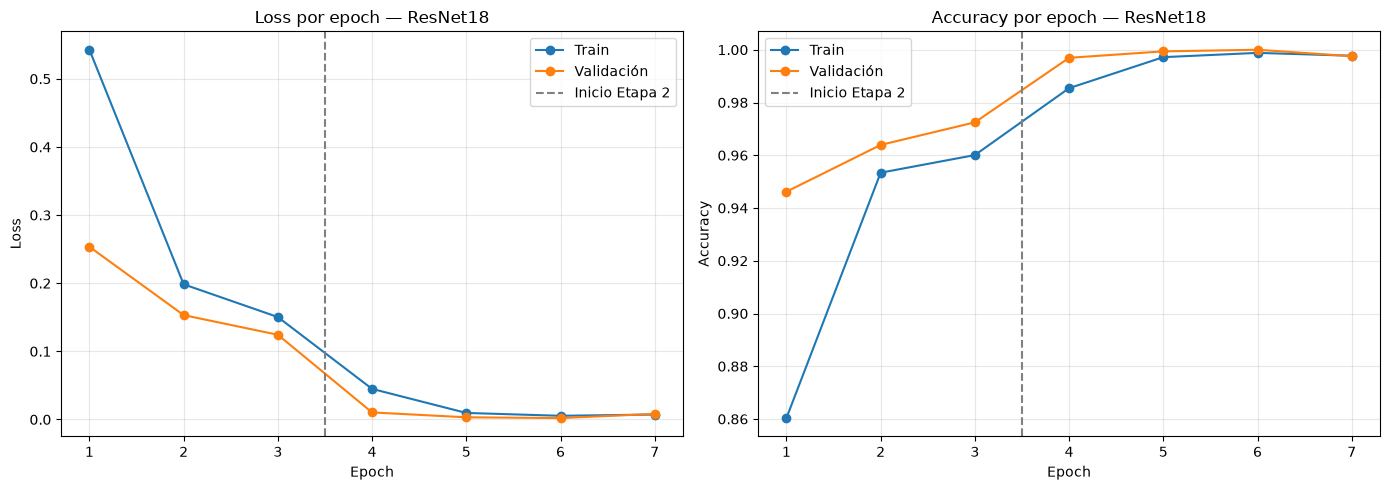

In [9]:
epochs_x = range(1, len(historial["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ax, clave, titulo in [(ax1, "loss", "Loss"), (ax2, "acc", "Accuracy")]:
    ax.plot(epochs_x, historial[f"train_{clave}"], "o-", label="Train")
    ax.plot(epochs_x, historial[f"val_{clave}"], "o-", label="Validación")
    if HACER_ETAPA2:
        ax.axvline(EPOCHS_CABEZA + 0.5, color="gray", ls="--", label="Inicio Etapa 2")  # Separación entre etapas
    ax.set_title(f"{titulo} por epoch — ResNet18"); ax.set_xlabel("Epoch"); ax.set_ylabel(titulo)
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "curvas_resnet18.png", dpi=120)
plt.show()

## 10. Evaluación en test

Las mismas métricas que en el notebook 01: accuracy, `classification_report` y matriz de confusión.

Accuracy en test: 99.85%  (2694 de 2698)

                 precision    recall  f1-score   support

 Manzana fresca      0.997     1.000     0.999       395
  Banana fresca      1.000     1.000     1.000       381
 Naranja fresca      0.997     0.997     0.997       388
Manzana podrida      0.997     1.000     0.998       601
 Banana podrida      1.000     1.000     1.000       530
Naranja podrida      1.000     0.993     0.996       403

       accuracy                          0.999      2698
      macro avg      0.999     0.998     0.998      2698
   weighted avg      0.999     0.999     0.999      2698



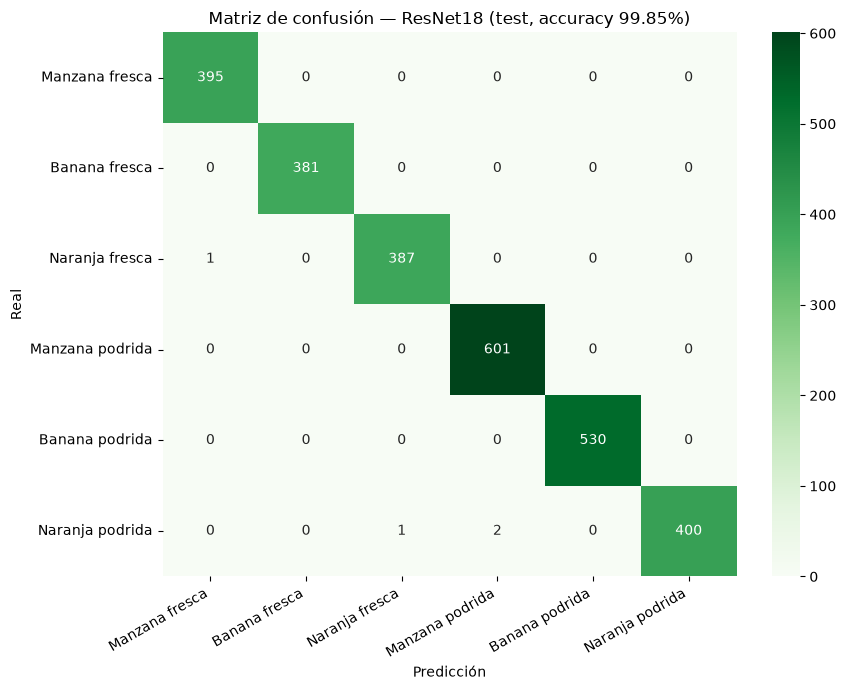

In [10]:
modelo.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        probs = torch.softmax(modelo(inputs.to(device)), dim=1)  # Logits -> probabilidades
        all_probs.append(probs.cpu()); all_preds.append(probs.argmax(1).cpu()); all_labels.append(labels)
all_probs = torch.cat(all_probs).numpy()
all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {accuracy * 100:.2f}%  ({(all_preds == all_labels).sum()} de {len(all_labels)})\n")
print(classification_report(all_labels, all_preds, target_names=nombres, digits=3))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=nombres, yticklabels=nombres)
plt.xlabel("Predicción"); plt.ylabel("Real")
plt.title(f"Matriz de confusión — ResNet18 (test, accuracy {accuracy*100:.2f}%)")
plt.xticks(rotation=30, ha="right"); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "matriz_confusion_resnet18.png", dpi=120)
plt.show()

## 11. Predicciones visuales y errores

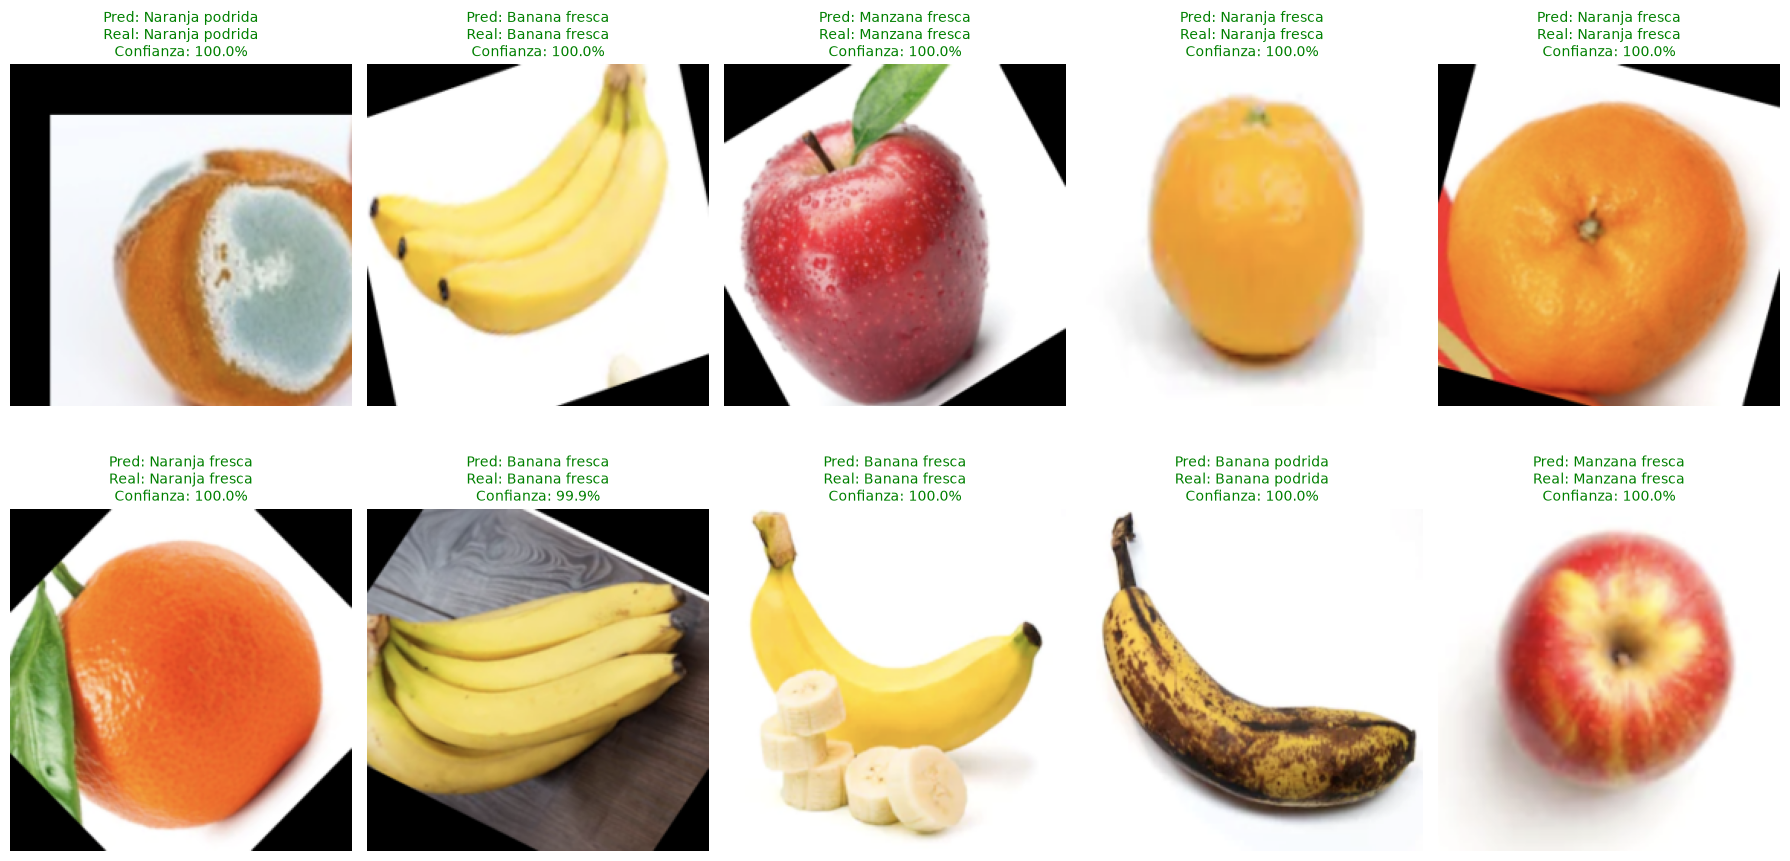

Errores: 4 de 2698 (0.15%)
    2 veces:  real = Naranja podrida -> predicho = Manzana podrida
    1 veces:  real = Naranja podrida -> predicho = Naranja fresca
    1 veces:  real = Naranja fresca  -> predicho = Manzana fresca


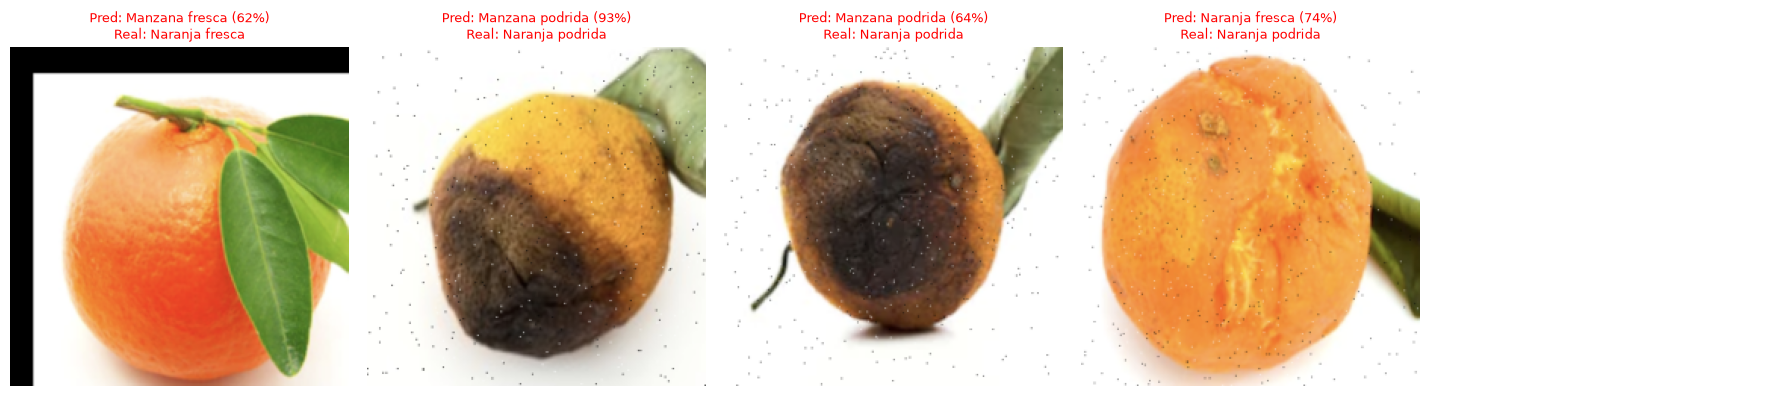

In [11]:
idx_azar = random.sample(range(len(test_dataset)), 10)  # 10 imágenes al azar
fig, axes = plt.subplots(2, 5, figsize=(18, 9.5))
for ax, idx in zip(axes.flat, idx_azar):
    image, real = test_dataset[idx]
    pred = all_preds[idx]
    ax.imshow(desnormalizar(image))
    ax.set_title(f"Pred: {nombres[pred]}\nReal: {nombres[real]}\nConfianza: {all_probs[idx, pred]:.1%}",
                 color="green" if pred == real else "red", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

errores = np.where(all_preds != all_labels)[0]  # Índices mal clasificados
print(f"Errores: {len(errores)} de {len(all_labels)} ({100 * len(errores) / len(all_labels):.2f}%)")
pares = [(cm[i, j], nombres[i], nombres[j]) for i in range(len(clases)) for j in range(len(clases)) if i != j and cm[i, j] > 0]
for n, real, pred in sorted(pares, reverse=True)[:6]:
    print(f"  {n:3d} veces:  real = {real:15s} -> predicho = {pred}")

if len(errores) > 0:
    muestra = errores[:15]
    filas = (len(muestra) + 4) // 5
    fig, axes = plt.subplots(filas, 5, figsize=(18, 3.8 * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, muestra):
        image, real = test_dataset[idx]
        pred = all_preds[idx]
        ax.imshow(desnormalizar(image))
        ax.set_title(f"Pred: {nombres[pred]} ({all_probs[idx, pred]:.0%})\nReal: {nombres[real]}", color="red", fontsize=9)
    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / "errores_resnet18.png", dpi=100)
    plt.show()

## 12. Predicción con fotos propias

Es la misma idea que en el notebook 01, pero con el preprocesamiento de ResNet18 (224 y normalización de ImageNet). Así podemos comparar los dos modelos con **las mismas fotos reales**, que es la comparación más honesta.

In [12]:
def predecir_imagen(ruta):
    """Abre una foto, la preprocesa como el test de ResNet18 y devuelve (imagen, probabilidades)."""
    img = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")  # Corrige la orientación del celular y pasa a RGB
    x = test_transform(img).unsqueeze(0).to(device)  # Preprocesa y agrega la dimensión de batch
    modelo.eval()
    with torch.no_grad():
        return img, torch.softmax(modelo(x), dim=1)[0].cpu().numpy()

fotos = sorted(p for p in (RAIZ / "imagenes_prueba").glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})
if not fotos:
    print("No hay fotos en imagenes_prueba/. Agrega algunas y vuelve a ejecutar esta celda.")
else:
    columnas = min(len(fotos), 4)
    filas = (len(fotos) + columnas - 1) // columnas
    fig, axes = plt.subplots(filas, columnas, figsize=(4.5 * columnas, 5 * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, ruta in zip(axes.flat, fotos):
        img, probs = predecir_imagen(ruta)
        top = probs.argmax()
        veredicto = "DESCARTAR" if clases[top].startswith("rotten") else "APTA PARA VENTA"
        ax.imshow(img)
        ax.set_title(f"{ruta.name}\n{nombres[top]} ({probs[top]:.1%})\n{veredicto}",
                     color="red" if veredicto == "DESCARTAR" else "green", fontsize=10)
    plt.tight_layout()
    plt.show()

No hay fotos en imagenes_prueba/. Agrega algunas y vuelve a ejecutar esta celda.


## 13. Guardar el modelo

In [13]:
ruta_pesos = MODELS_DIR / "frutas_resnet18.pth"
if QUICK_RUN:
    print("QUICK_RUN: el modelo NO se guarda.")
else:
    torch.save(modelo.state_dict(), ruta_pesos)  # Solo los pesos (para cargarlo: resnet18(), cambiar fc y load_state_dict)
    print(f"Modelo guardado en {ruta_pesos} ({ruta_pesos.stat().st_size / 1e6:.1f} MB)")

Modelo guardado en ..\models\frutas_resnet18.pth (44.8 MB)


## 14. Tabla comparativa: CNN propia vs ResNet18

Comparamos los dos modelos en lo que importa para llevarlos a producción:
- **Accuracy en test:** qué tan bien clasifica.
- **Parámetros y tamaño en MB:** cuánta memoria y disco necesita (importa para subir la app a internet o usarla en un celular).
- **Tiempo de entrenamiento.**
- **Tiempo de inferencia por imagen:** cuánto tarda en responder con **una** foto, que es lo que hace la app. Lo medimos en GPU y en **CPU**, porque un servidor gratuito (como Hugging Face Spaces) normalmente no tiene GPU.

Para medir la inferencia hacemos primero unas pasadas de "calentamiento" (la primera llamada siempre es más lenta) y luego promediamos 50 pasadas. En GPU hace falta `torch.cuda.synchronize()`, porque la GPU trabaja de forma asíncrona y sin esperarla mediríamos mal el tiempo.

In [14]:
sys.path.append(str(RAIZ.resolve()))  # Para importar la CNN propia
from src.modelo import Net

# ---- Cargar la CNN propia entrenada en el notebook 01 ----
cnn = Net(n_clases=len(clases))
cnn.load_state_dict(torch.load(MODELS_DIR / "frutas_cnn.pth", map_location="cpu"))  # Pesos guardados en el notebook 01
cnn.eval()
metricas_cnn = json.loads((OUTPUTS_DIR / "metricas_cnn.json").read_text(encoding="utf-8"))  # Métricas reales del notebook 01

def tiempo_inferencia(m, tamano, dispositivo, repeticiones=50):
    """Milisegundos promedio para predecir UNA imagen (batch de 1)."""
    m = m.to(dispositivo).eval()
    x = torch.randn(1, 3, tamano, tamano, device=dispositivo)  # Una imagen falsa
    with torch.no_grad():
        for _ in range(10):  # Calentamiento
            m(x)
        if dispositivo.type == "cuda":
            torch.cuda.synchronize()  # Espera a que la GPU termine
        t0 = time.perf_counter()
        for _ in range(repeticiones):
            m(x)
        if dispositivo.type == "cuda":
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / repeticiones * 1000  # Promedio en ms

cpu = torch.device("cpu")
tiempos = {
    "cnn": (tiempo_inferencia(cnn, 128, device), tiempo_inferencia(cnn, 128, cpu)),
    "resnet": (tiempo_inferencia(modelo, IMG_SIZE, device), tiempo_inferencia(modelo, IMG_SIZE, cpu)),
}
modelo.to(device)  # Devolvemos ResNet18 a la GPU

tamano_resnet = ruta_pesos.stat().st_size / 1e6 if ruta_pesos.exists() else float("nan")
epochs_resnet = EPOCHS_CABEZA + (EPOCHS_FINE if HACER_ETAPA2 else 0)

filas = [
    ("Accuracy en test", f"{metricas_cnn['test_accuracy']*100:.2f}%", f"{accuracy*100:.2f}%"),
    ("Parámetros totales", f"{metricas_cnn['parametros']:,}", f"{n_total:,}"),
    ("Tamaño del .pth", f"{metricas_cnn['tamano_mb']:.1f} MB", f"{tamano_resnet:.1f} MB"),
    ("Tamaño de imagen", "128x128", f"{IMG_SIZE}x{IMG_SIZE}"),
    ("Epochs", f"{metricas_cnn['epochs']}", f"{epochs_resnet} ({EPOCHS_CABEZA} + {EPOCHS_FINE if HACER_ETAPA2 else 0})"),
    ("Tiempo de entrenamiento", f"{metricas_cnn['tiempo_entrenamiento_s']/60:.1f} min", f"{tiempo_entrenamiento/60:.1f} min"),
    ("Inferencia por imagen (GPU)", f"{tiempos['cnn'][0]:.2f} ms", f"{tiempos['resnet'][0]:.2f} ms"),
    ("Inferencia por imagen (CPU)", f"{tiempos['cnn'][1]:.2f} ms", f"{tiempos['resnet'][1]:.2f} ms"),
]
print(f"{'Métrica':<30}{'CNN propia':>20}{'ResNet18':>22}")
print("-" * 72)
for nombre, a, b in filas:
    print(f"{nombre:<30}{a:>20}{b:>22}")

if not QUICK_RUN:  # Guardamos las métricas reales para el README
    metricas = {"modelo": "ResNet18 (transfer learning)", "test_accuracy": round(float(accuracy), 4),
                "mejor_val_accuracy": round(float(mejor["acc"]), 4), "mejor_epoch": mejor["epoch"],
                "epochs": epochs_resnet, "parametros": n_total, "tamano_mb": round(tamano_resnet, 1),
                "tiempo_entrenamiento_s": round(tiempo_entrenamiento, 1),
                "inferencia_ms_gpu": round(tiempos["resnet"][0], 2), "inferencia_ms_cpu": round(tiempos["resnet"][1], 2),
                "cnn_inferencia_ms_gpu": round(tiempos["cnn"][0], 2), "cnn_inferencia_ms_cpu": round(tiempos["cnn"][1], 2)}
    (OUTPUTS_DIR / "metricas_resnet18.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")

Métrica                                 CNN propia              ResNet18
------------------------------------------------------------------------
Accuracy en test                            99.07%                99.85%
Parámetros totales                      16,875,526            11,179,590
Tamaño del .pth                            67.5 MB               44.8 MB
Tamaño de imagen                           128x128               224x224
Epochs                                          20             7 (3 + 4)
Tiempo de entrenamiento                    3.0 min               1.4 min
Inferencia por imagen (GPU)                0.63 ms               2.74 ms
Inferencia por imagen (CPU)                2.63 ms              12.94 ms


## 15. Conclusión: ¿cuál conviene?

| Métrica | CNN propia | ResNet18 |
|---|---:|---:|
| Accuracy en test | 99.07% (25 errores) | **99.85%** (4 errores) |
| Parámetros | 16.9 M | **11.2 M** |
| Tamaño del `.pth` | 67.5 MB | **44.8 MB** |
| Epochs | 20 | **7** (3 + 4) |
| Tiempo de entrenamiento | 3.0 min | **1.4 min** |
| Inferencia por imagen (GPU) | **0.63 ms** | 2.74 ms |
| Inferencia por imagen (CPU) | **2.63 ms** | 12.94 ms |

1. **ResNet18 es mejor en casi todo:** comete **6 veces menos errores**, tiene **menos parámetros**, pesa menos y se entrenó en menos de la mitad del tiempo, con 7 epochs en lugar de 20. Así se responde en la práctica la pregunta *"¿cómo mejorar la accuracy?"*: **transfer learning**.
2. **¿Por qué tiene menos parámetros siendo mucho más profunda (18 capas contra 5)?** Por el *global average pooling*: su capa final recibe solo 512 números, mientras que nuestro `fc1` recibe 32,768 y concentra 16.8M de parámetros.
3. **La Etapa 2 (fine-tuning de `layer4`) fue clave:** solo con la cabeza entrenada llegó a 97.2% en validación; al descongelar `layer4`, en el primer epoch ya subió a 99.7%.
4. **Su único punto en contra es la velocidad:** es ~4-5 veces más lenta por imagen, porque procesa imágenes de 224x224 con muchas más capas. Igual, **13 ms en CPU** es instantáneo para una app que analiza una foto a la vez.
5. **Recomendación:** usar **ResNet18 en la app**. Ojo: como el test tiene *data leakage* (ver el notebook 01), la diferencia entre 99.07% y 99.85% es de solo 21 imágenes de variantes de fotos conocidas. **La comparación decisiva es con fotos propias** (sección 12 de los dos notebooks). Lo esperable es que ResNet18 generalice mejor a fotos reales, porque sus filtros aprendieron con 1.2M de imágenes variadas, pero hay que comprobarlo.